# Project A INAIL 1 timing and target readiness V2
Run all cells. All outputs are saved inside the Project A working directory. Source recordings are read without modification. This notebook independently rechecks the MATLAB files and produces timing diagnostics, duplicate comparisons, filtered MVC candidates, channel/trial ledgers, review templates and a shareable ZIP.

V2 investigates timing but cannot establish a common clock from unequal recording lengths. It does not choose alignment from EMG–movement correlation. No physiological training target is approved without documented alignment, event interpretation and channel review. Filtered MVC values are diagnostic normalization candidates, not certified maximal contractions. No models are trained.

Dependencies: `numpy pandas scipy matplotlib openpyxl`. Protocol extraction uses Python's built-in XML reader, so `python-docx` is not required. Code cells contain no comments.

Keep the raw data at the configured DATA_ROOT. Moving the V1 ZIP does not move the raw dataset. Save this notebook in PROJECT_ROOT. After running, upload the resulting V2 ZIP and the executed notebook.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
from collections import defaultdict
import hashlib
import json
import re
import sys
import platform
import traceback
import zipfile
import importlib.metadata
import xml.etree.ElementTree as ET
import numpy as np
import pandas as pd
from scipy.io import loadmat, whosmat
from scipy.signal import butter, sosfiltfilt, welch
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = Path("/home/rafsan/Documents/GitHub/IPEXBIO/Project_A")
DATA_ROOT = Path.home() / "Downloads/INAIL_1/Dataset1/DATA"
ALIGNMENT_REVIEW_CSV = None
CHANNEL_REVIEW_CSV = None
MAX_DIAGNOSTIC_FIGURES = 14
EXPECTED_SUBJECTS = 17
EXPECTED_EMG = ["RESL", "RESI", "RM", "RLD", "RRAS", "RRAM", "REO", "RIO", "LESL", "LESI", "LM", "LLD", "LRAS", "LRAM", "LEO", "LIO"]

PROJECT_ROOT = PROJECT_ROOT.expanduser().resolve()
DATA_ROOT = DATA_ROOT.expanduser().resolve()
if not DATA_ROOT.is_dir():
    raise FileNotFoundError(f"Edit DATA_ROOT to the raw DATA directory: {DATA_ROOT}")
PROJECT_ROOT.mkdir(parents=True, exist_ok=True)
RUN_DIR = PROJECT_ROOT / "results" / "INAIL1_Readiness_V2" / datetime.now(timezone.utc).strftime("run_%Y%m%dT%H%M%S_%fZ")
RUN_DIR.mkdir(parents=True, exist_ok=False)
FIG_DIR = RUN_DIR / "figures"
FIG_DIR.mkdir()
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 35)
print("Project:", PROJECT_ROOT)
print("Raw data:", DATA_ROOT)
print("Results:", RUN_DIR)

Project: /home/rafsan/Documents/GitHub/IPEXBIO/Project_A
Raw data: /home/rafsan/Downloads/INAIL_1/Dataset1/DATA
Results: /home/rafsan/Documents/GitHub/IPEXBIO/Project_A/results/INAIL1_Readiness_V2/run_20261113T052750_196646Z


## Independent file inventory and reusable audit functions

In [2]:
def subject_id(value):
    match = re.search(r"(?:^|[^A-Za-z])S0*(\d+)", str(value), flags=re.I)
    return f"S{int(match.group(1)):02d}" if match else None

def ignored(path):
    return "__MACOSX" in path.parts or path.name.startswith("._")

def file_hash(path):
    h = hashlib.sha256()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

all_files = sorted(p for p in DATA_ROOT.rglob("*") if p.is_file() and not ignored(p))
manifest = pd.DataFrame([{"relative_path": str(p.relative_to(DATA_ROOT)), "extension": p.suffix.lower(), "bytes": p.stat().st_size} for p in all_files])
mat_files = sorted([p for p in all_files if p.suffix.lower() == ".mat" and p.name.lower().endswith("_all_trials.mat")], key=lambda p: (subject_id(p.name) or "", str(p)))
if not mat_files:
    raise FileNotFoundError("No *_all_trials.mat exports found recursively under DATA_ROOT")
file_inventory = pd.DataFrame([{"subject": subject_id(p.name), "file": str(p.relative_to(DATA_ROOT)), "bytes": p.stat().st_size} for p in mat_files])
display(file_inventory)
display(manifest.groupby("extension", dropna=False).agg(files=("bytes", "size"), bytes=("bytes", "sum")))
print("Distinct filename participant IDs:", file_inventory.subject.nunique(), "advertised:", EXPECTED_SUBJECTS)
print("Repeated participant IDs across files:", file_inventory[file_inventory.subject.duplicated(False)].to_dict("records"))

,subject,file,bytes
0,S01,S01/Exported/mat_format/S01_all_trials.mat,29401843
1,S02,S02/Exported/mat_format/S02_all_trials.mat,27572975
2,S03,S03/Exported/mat_format/S03_all_trials.mat,25839487
3,S04,S04/Exported/mat_format/S04_all_trials.mat,29222915
4,S05,S05/Exported/mat_format/S05_all_trials.mat,24613336
5,S06,S06/Exported/mat_format/S06_all_trials.mat,29128217
6,S07,S07/Exported/mat_format/S07_all_trials.mat,25187090
7,S08,S08/Exported/mat_format/S08_all_trials.mat,39785623
8,S09,S09/Exported/mat_format/S09_all_trials.mat,38534845
9,S10,S010/Exported/mat_format/S10_all_trials.mat,31144459


,files,bytes
extension,,
,42,266408
.mat,17,434264806
.tdf,132,263378624
.xlsx,1,9310


Distinct filename participant IDs: 17 advertised: 17
Repeated participant IDs across files: []


In [3]:
def entries(value):
    if isinstance(value, dict):
        return [value]
    if isinstance(value, (list, tuple)):
        return list(value)
    if isinstance(value, np.ndarray):
        return list(value.reshape(-1))
    return []

def numeric(value):
    a = np.asarray(value)
    return a if a.dtype.kind in "biufc" else None

def leaves(value, prefix=""):
    if isinstance(value, dict):
        for key, item in value.items():
            yield from leaves(item, f"{prefix}.{key}" if prefix else key)
    else:
        a = numeric(value)
        if a is not None:
            yield prefix, a

def digest(value):
    h = hashlib.sha256()
    count = 0
    for name, a in sorted(leaves(value)):
        h.update(name.encode())
        h.update(str(a.shape).encode())
        h.update(a.dtype.str.encode())
        h.update(np.ascontiguousarray(a).tobytes())
        count += a.size
    return h.hexdigest() if count else None

def scalar(value):
    try:
        a = np.asarray(value)
        return float(a.reshape(-1)[0]) if a.size == 1 else np.nan
    except Exception:
        return np.nan

def rate(value):
    r = scalar(value)
    return r if np.isfinite(r) and r > 0 else np.nan

def longest_run(mask):
    padded = np.r_[False, np.asarray(mask, dtype=bool).reshape(-1), False]
    edges = np.flatnonzero(padded[1:] != padded[:-1])
    return int(np.max(edges[1::2] - edges[::2])) if edges.size else 0

def quality(a, fs):
    a = np.asarray(a)
    values = np.real(a).astype(float)
    flat = values.reshape(-1)
    good = flat[np.isfinite(flat)]
    row_bad = ~np.isfinite(values) if values.ndim <= 1 else ~np.isfinite(values).reshape(values.shape[0], -1).all(axis=1)
    result = {"shape": str(tuple(a.shape)), "dtype": str(a.dtype), "samples": int(a.shape[0]) if a.ndim else 1, "elements": int(a.size), "nonfinite_fraction": float(1 - len(good) / a.size) if a.size else np.nan, "longest_missing_samples": longest_run(row_bad), "fs": fs}
    result["duration_s"] = result["samples"] / fs if np.isfinite(fs) and a.size else np.nan
    if good.size:
        result.update(minimum=float(np.min(good)), maximum=float(np.max(good)), mean=float(np.mean(good)), std=float(np.std(good)), rms=float(np.sqrt(np.mean(good ** 2))), abs_p95=float(np.percentile(np.abs(good), 95)), extreme_value_fraction=float(np.mean((good == good.min()) | (good == good.max()))))
        if values.ndim == 1 and len(values) > 1:
            valid = np.isfinite(values[:-1]) & np.isfinite(values[1:])
            result["equal_adjacent_fraction"] = float(np.mean(np.diff(values)[valid] == 0)) if valid.any() else np.nan
    return result

def moving_rms_reference(a, fs):
    a = np.asarray(a, dtype=float).reshape(-1)
    if not np.isfinite(fs) or len(a) < 2 or not np.isfinite(a).all():
        return np.nan
    a = a - np.mean(a)
    width = max(1, min(len(a), int(round(0.25 * fs))))
    rms = np.sqrt(np.maximum(0, np.convolve(a ** 2, np.ones(width) / width, mode="valid")))
    return float(np.percentile(rms, 95))

def describe_schema(value, path="root", depth=0):
    if depth > 6:
        return []
    if isinstance(value, dict):
        rows = [{"path": path, "kind": "dict", "detail": list(value)}]
        for key, item in value.items():
            rows.extend(describe_schema(item, f"{path}.{key}", depth+1))
        return rows
    if isinstance(value, (list, tuple)):
        return [{"path": path, "kind": "list", "detail": len(value)}] + (describe_schema(value[0], path + "[0]", depth+1) if value else [])
    if isinstance(value, np.ndarray):
        return [{"path": path, "kind": "array", "detail": {"shape": list(value.shape), "dtype": str(value.dtype)}}]
    return [{"path": path, "kind": type(value).__name__, "detail": str(value)[:200]}]

GROUPS = {"Kinematic_data": ("data_3D", "fs_3D"), "sEMG": ("data_sEMG", "fs_sEMG"), "Ground_forces_and_moments": ("platform_data", "fs_forces"), "MVC": ("MVC_data", "fs_MVC")}

## Protocol extraction and source metadata
This extraction preserves table cells, text and native Word equation text. Embedded equation images are listed for manual inspection. Raw TDF headers are not decoded; source-file paths are inventoried for subsequent timing investigation.

In [4]:
protocol = []
for p in sorted(DATA_ROOT.parent.glob("*.docx")):
    with zipfile.ZipFile(p) as archive:
        ns = {"w":"http://schemas.openxmlformats.org/wordprocessingml/2006/main", "m":"http://schemas.openxmlformats.org/officeDocument/2006/math"}
        root = ET.fromstring(archive.read("word/document.xml"))
        text = ["".join(el.itertext()) for el in root.findall(".//w:t", ns)]
        paragraphs = ["".join(el.itertext()) for el in root.findall(".//w:p", ns)]
        tables = []
        for table in root.findall(".//w:tbl", ns):
            tables.append([[" ".join(x.text or "" for x in cell.findall(".//w:t", ns)) for cell in row.findall("w:tc", ns)] for row in table.findall("w:tr", ns)])
        equations = ["".join(x.text or "" for x in eq.findall(".//m:t", ns)) for eq in root.findall(".//m:oMath", ns)]
        protocol.append({"file":p.name,"sha256":file_hash(p),"paragraphs":paragraphs,"tables":tables,"equations":equations,"embedded_media":[name for name in archive.namelist() if name.startswith("word/media/")]})
        print("Protocol:", p.name)
        print("\n".join(paragraphs))
        for table in tables:
            display(pd.DataFrame(table))
workbooks = []
for p in all_files:
    if p.suffix.lower() == ".xlsx":
        try:
            for sheet, frame in pd.read_excel(p, sheet_name=None, header=None).items():
                workbooks.append({"file":str(p.relative_to(DATA_ROOT)),"sheet":sheet,"cells":frame.fillna("").astype(str).values.tolist()})
                print(p.name,sheet)
                display(frame)
        except Exception as exc:
            workbooks.append({"file":p.name,"error":str(exc)})
tdf_inventory = pd.DataFrame([{"path":str(p.relative_to(DATA_ROOT)),"bytes":p.stat().st_size} for p in all_files if p.suffix.lower()==".tdf"])
print("TDF source files:",len(tdf_inventory))

Protocol: Dataset1_Lifting_and_carrying.docx
Task Description
1.1 Task conditions
Each subject executed the tasks lifting a load using both hands (i.e. S05_Lift_LI1_1 where 5 is the number of the subject, LI1 is the level of risk, _1 is the number of repetition). 
1.2 Risk conditions
The lifting tasks were executed at three different risk levels.
The three lifting risk conditions were determined according to the Revised NIOSH Lifting Equation (Waters et al., 1993, 1994). The three lifting risk conditions were chosen to obtain Lifting Index (LI) values of 1, 2, and 3 (Table 1). LI is calculated as the ratio between the load weight (L) and the Recommended Weight Limit (RWL) expressed by the following equations (Waters et al., 1993, 1994):
LI=LRWL
RWL=LC x HM x VM x DM x AM x FM x CM
where the Load Costant (LC, 23 kg) is weighted by the Horizontal (HM), Vertical (VM), Vertical Travel Distance (DM), Asymmetry Angle (AM), lifting frequency (FM) and Hand-to-object Coupling (CM) Multipliers. 

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
0,,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None
1,Task,LC (kg),H (cm),HM,V (cm),VM,D (cm),DM,A (°),AM,F (lift/min),FM,C,CM,L (kg),RWL,LI,None
2,,,,,,,,,,,,,,,,,,
3,A,23,25,1.00,75,1.00,25,1.00,0,1,≤2,1,good,1,23,23.00,1.00,None
4,B,23,50,0.50,75,1.00,25,1.00,0,1,≤2,1,good,1,23,11.50,2.00,None
5,C,23,63,0.40,30,0.87,45,0.92,0,1,≤2,1,good,1,22.09,7.36,3.00,None


,0,1,2
0,,None,None
1,Data type,Proprietary,Exported
2,Kinematic (optoelectronic system ),.TDF,.mat
3,G round reaction forces and moments (force pl...,.TDF,.mat
4,sEMG,.TDF,.mat


Subjects_info.xlsx Foglio1


,0,1,2,3,4,5
0,Participant,Weight (kg),Height (m),BMI (kg/m2),Age (years),Gender
1,S01,68,1.71,23.255019,37,M
2,S02,85,1.84,25.106333,30,M
3,S03,94,1.85,27.465303,42,M
4,S04,92,1.73,30.739417,43,M
5,S05,80,1.86,23.124061,23,M
6,S06,73,1.78,23.04002,27,M
7,S07,82,1.77,26.173833,24,M
8,S08,85,1.95,22.353715,27,M
9,S09,75,1.78,23.671254,41,M


TDF source files: 132


## Signal processing and review input validation
Diagnostic EMG preprocessing is demeaning followed by a fourth-order 20–450 Hz Butterworth bandpass at the recorded 1000 Hz rate, with a Nyquist-aware upper limit. No notch is applied automatically. MVC reference candidates use the 95th percentile of a 250 ms moving RMS. A ratio above 2 between contraction references is a review flag, not a validated physiological cutoff.

For documented review, set the configuration paths to completed CSV templates from an earlier run. Alignment offset convention: `EMG elapsed seconds = movement elapsed seconds + emg_offset_s`. Source hashes bind decisions to the exact recordings. A reviewer must supply the actual evidence; editing a status alone does not validate alignment. Metadata acceptance is recorded as reviewer-supplied, not independently verified by software.''

In [5]:
def bandpassed(a, fs):
    a = np.asarray(a, dtype=float).reshape(-1)
    if len(a) < 64 or not np.isfinite(a).all() or not np.isfinite(fs) or fs <= 50:
        return None
    high = min(450.0, fs * 0.45)
    if high <= 20:
        return None
    return sosfiltfilt(butter(4,[20,high],btype="bandpass",fs=fs,output="sos"),a-a.mean())

def rms_trace(a, fs):
    width = max(1,min(len(a),int(round(0.25*fs))))
    return np.sqrt(np.maximum(0,np.convolve(a*a,np.ones(width)/width,mode="valid")))

def key_for(sid, task):
    return sid+"::"+str(task).lower().removesuffix(".tdf")

def read_review(path, required, key_columns):
    if path is None:
        return pd.DataFrame(columns=required)
    frame=pd.read_csv(Path(path).expanduser(),keep_default_na=False,dtype=str)
    missing=set(required)-set(frame.columns)
    if missing:
        raise ValueError(f"Review file missing columns: {sorted(missing)}")
    if frame.duplicated(key_columns).any():
        raise ValueError("Review file contains duplicate decision keys")
    return frame

alignment_columns=["trial_id","motion_sha256","emg_sha256","event_index_base","emg_offset_s","alignment_approved","evidence_source","reviewer"]
channel_review_columns=["subject","channel","mvc_sha256_1","mvc_sha256_2","channel_approved","reference_method","units_confirmed","evidence_source","reviewer"]
alignment_review=read_review(ALIGNMENT_REVIEW_CSV,alignment_columns,["trial_id"])
channel_review=read_review(CHANNEL_REVIEW_CSV,channel_review_columns,["subject","channel"])
alignment_lookup=alignment_review.set_index("trial_id").to_dict("index")
channel_lookup={(r["subject"],r["channel"]):r for r in channel_review.to_dict("records")}

def true(value):
    return str(value).strip().lower() in {"true","1","yes"}

## Trial timing hypotheses and MVC diagnostics

[1/17] S01


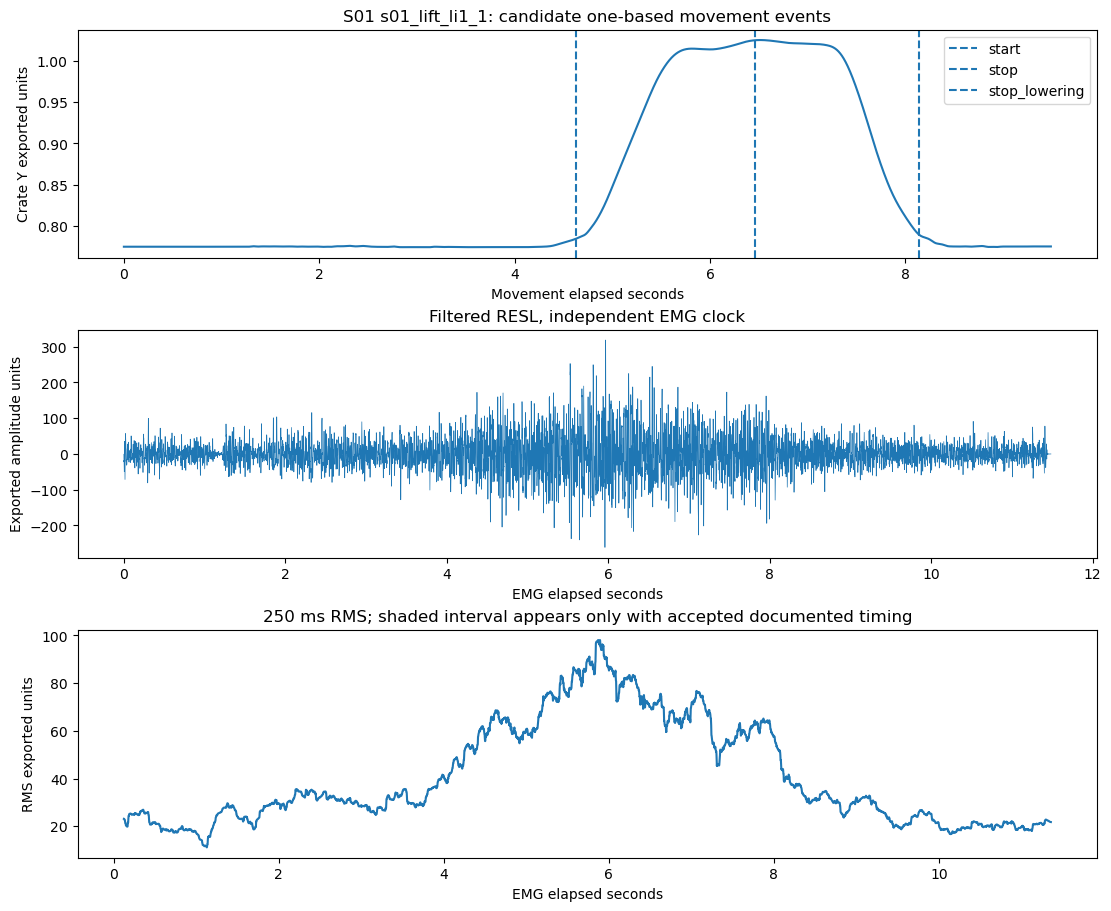

[2/17] S02


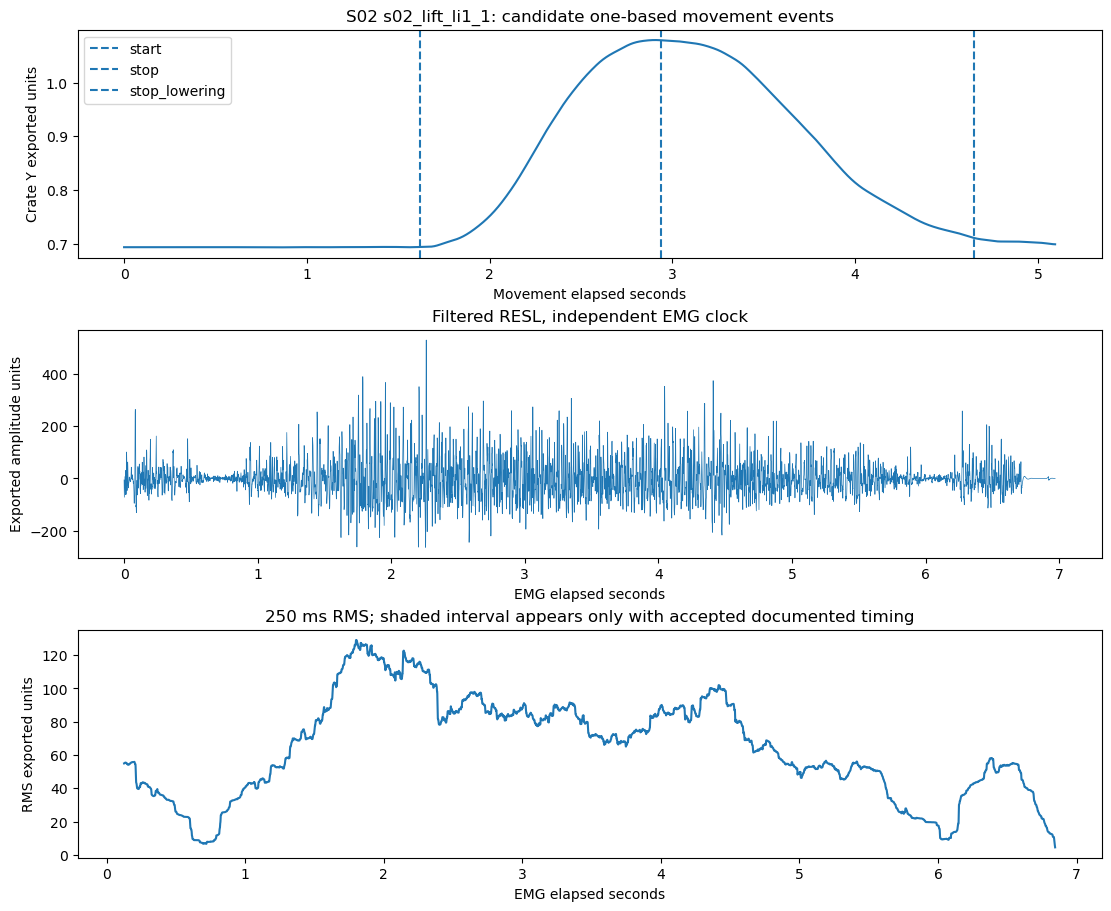

[3/17] S03


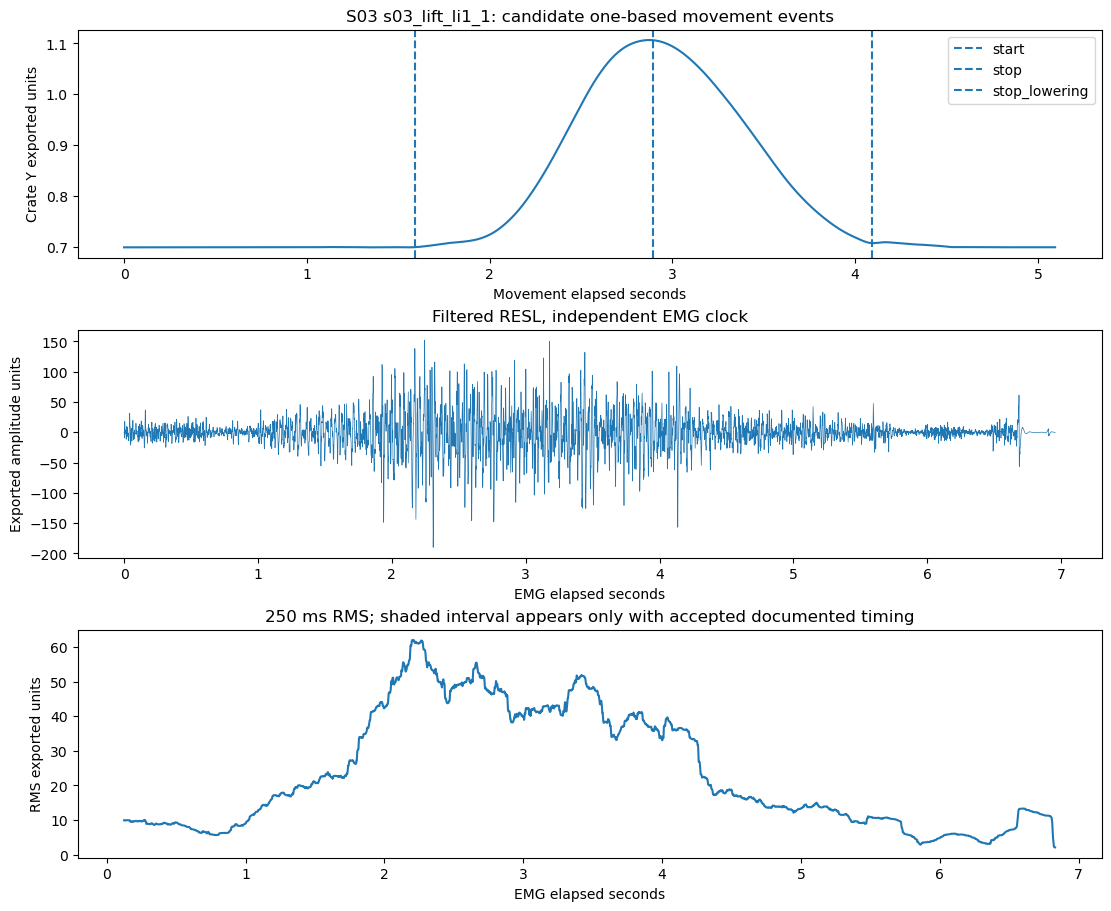

[4/17] S04


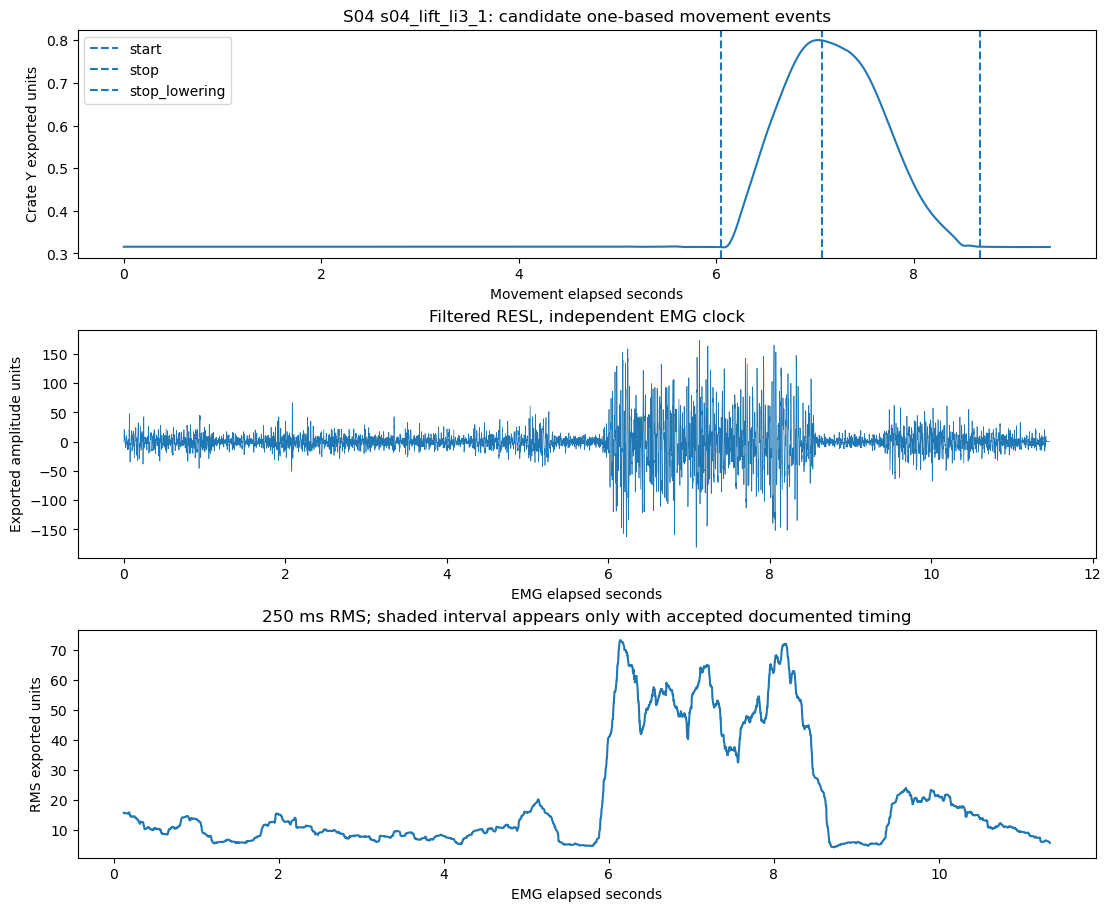

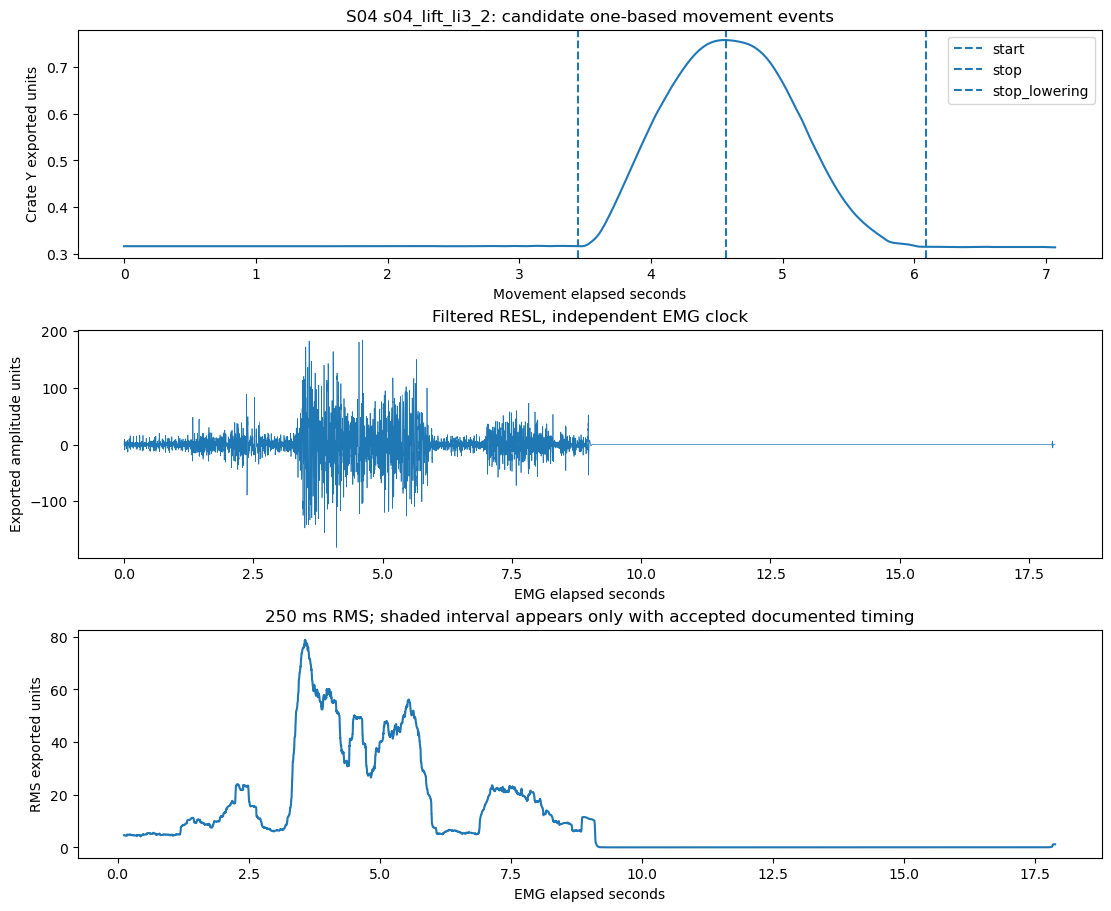

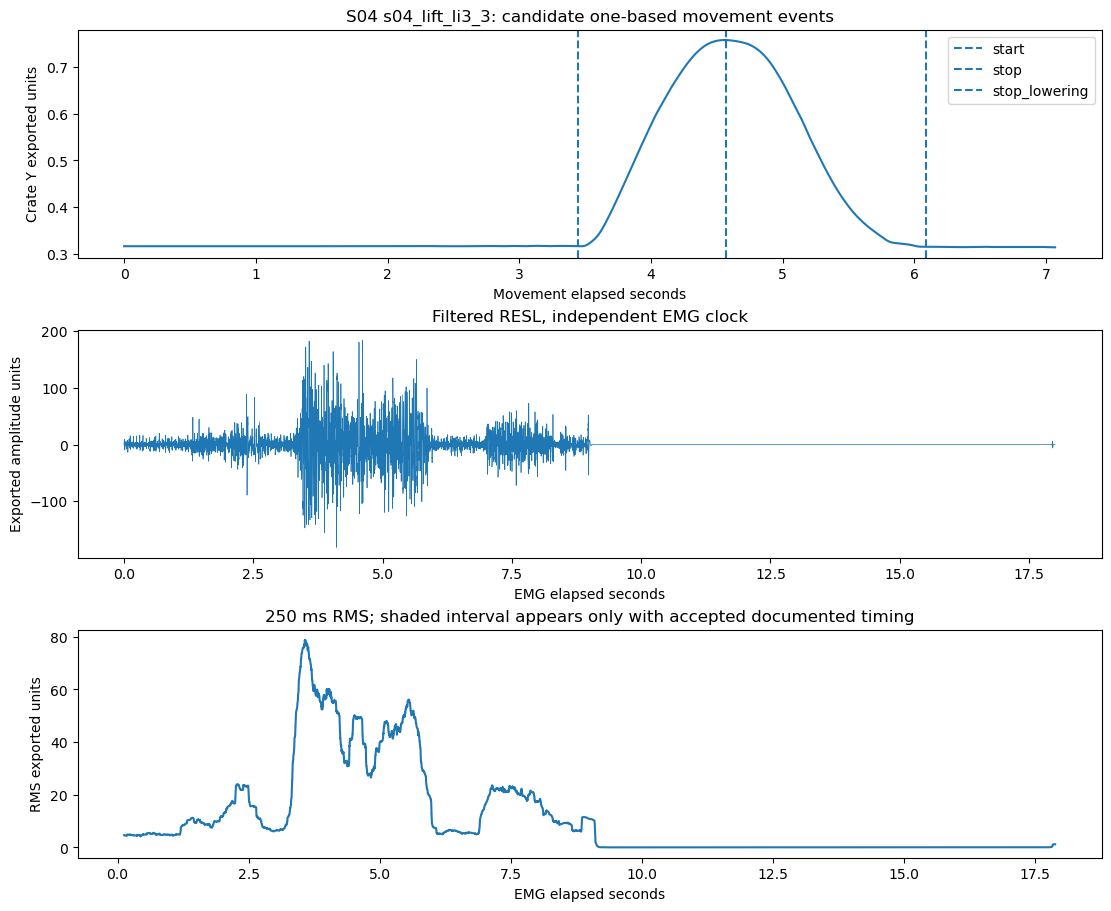

[5/17] S05
[6/17] S06
[7/17] S07
[8/17] S08
[9/17] S09
[10/17] S10
[11/17] S11
[12/17] S12


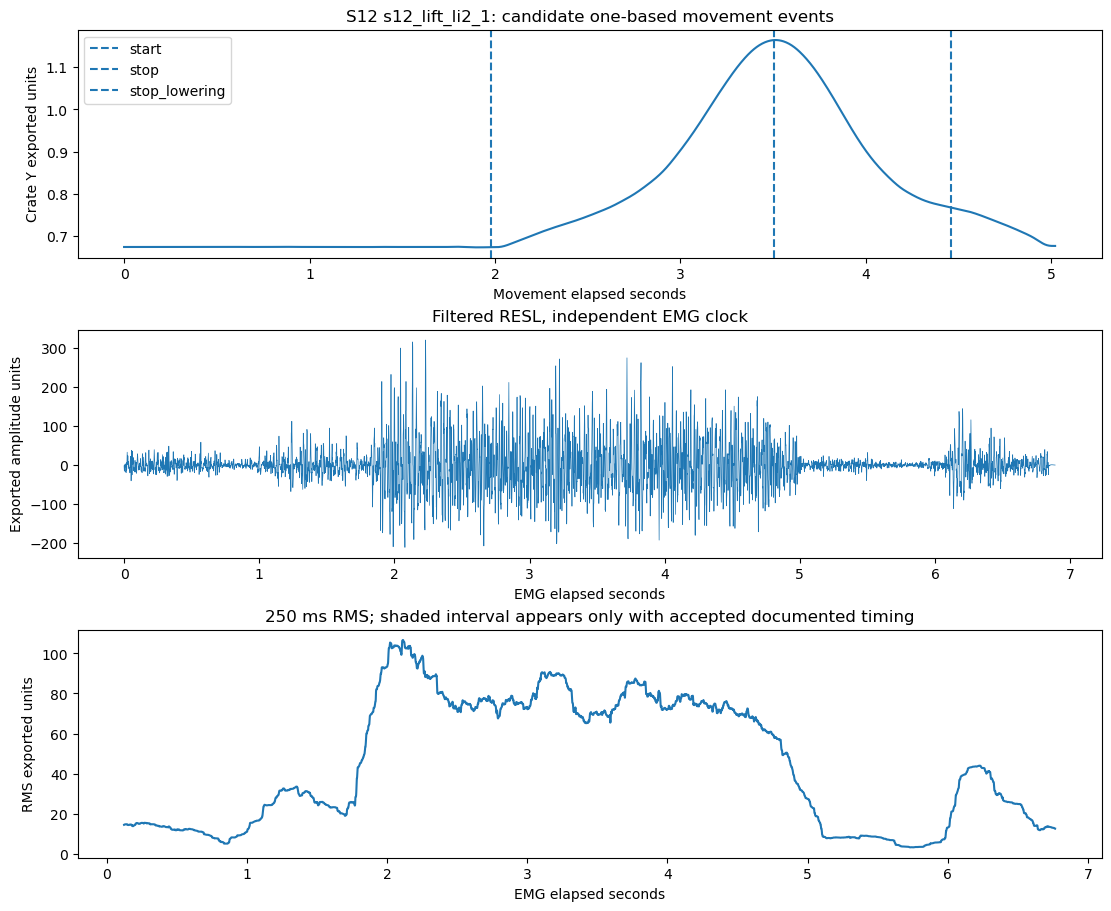

[13/17] S13
[14/17] S14
[15/17] S15
[16/17] S16


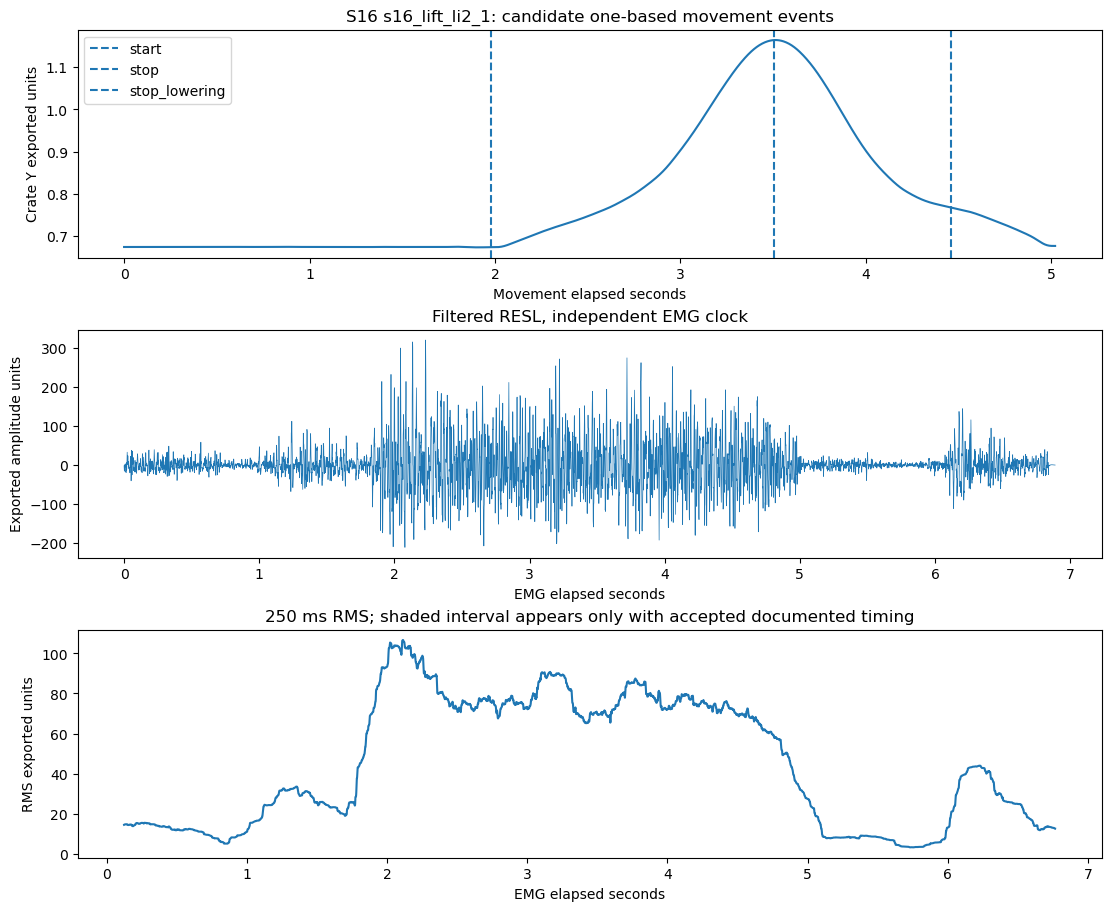

[17/17] S17


,subject,trial_id,task,LI,repetition,motion_sha256,emg_sha256,pair_valid,movement_finite,movement_samples,emg_samples,motion_fs,emg_fs,motion_seconds,emg_seconds,duration_difference_s,duration_ratio,events_json,events_ordered,one_based_bounds,zero_based_bounds,start_frame,stop_frame,stop_lowering_frame,candidate_lifting_duration_s,crate_y_delta_export_units,prescribed_vertical_travel_m,hypothesis_start_aligned_offset_s,hypothesis_end_aligned_offset_s,hypothesis_centered_offset_s,alignment_documented,review_hashes_match,approved_offset_s,approved_event_index_base,approved_emg_start_index,approved_emg_stop_exclusive,alignment_status
0,S01,S01::s01_lift_li1_1,s01_lift_li1_1,1,1,56f8a73e7d825d3625cc16fe48ea193e1adb7578df0444...,60f763311d30298c49e6567a581e47224c66f4fc8b32df...,True,True,3227,11482,340.0,1000.0,9.491176,11.482,1.990824,1.209755,"{""start"": 1576.0, ""stop"": 2199.0, ""stop_loweri...",True,True,True,1576.0,2199.0,2768.0,1.832353,0.240142,0.25,0.0,1.990824,0.995412,False,False,NaN,NaN,None,None,unresolved
1,S01,S01::s01_lift_li1_2,s01_lift_li1_2,1,2,13501669b9d1481b27fbd90c4e3e66a7a644e1915c6121...,a0245510228114040e7bacfe343917048f99a8a3ff8987...,True,True,2472,8921,340.0,1000.0,7.270588,8.921,1.650412,1.226998,"{""start"": 900.0, ""stop"": 1275.0, ""stop_lowerin...",True,True,True,900.0,1275.0,1835.0,1.102941,0.268790,0.25,0.0,1.650412,0.825206,False,False,NaN,NaN,None,None,unresolved
2,S01,S01::s01_lift_li1_3,s01_lift_li1_3,1,3,13501669b9d1481b27fbd90c4e3e66a7a644e1915c6121...,a0245510228114040e7bacfe343917048f99a8a3ff8987...,True,True,2472,8921,340.0,1000.0,7.270588,8.921,1.650412,1.226998,"{""start"": 905.0, ""stop"": 1275.0, ""stop_lowerin...",True,True,True,905.0,1275.0,1835.0,1.088235,0.267527,0.25,0.0,1.650412,0.825206,False,False,NaN,NaN,None,None,unresolved
3,S01,S01::s01_lift_li2_1,s01_lift_li2_1,2,1,988bbbaedf4a606b77788b054b862a722fc995a472e94e...,ae7133e3ae961f98703777ce6c326d0ec5884e2dbb5cc0...,True,True,1505,6449,340.0,1000.0,4.426471,6.449,2.022529,1.456917,"{""start"": 726.0, ""stop"": 980.0, ""stop_lowering...",True,True,True,726.0,980.0,1363.0,0.747059,0.253539,0.25,0.0,2.022529,1.011265,False,False,NaN,NaN,None,None,unresolved
4,S01,S01::s01_lift_li2_2,s01_lift_li2_2,2,2,467e82bc80b35dc6f64d8dd7b822a6954bd34bbd524df4...,5dfd9ac03a79f85057d96b7d6b59c8b85691a8da1e34e9...,True,True,1914,7428,340.0,1000.0,5.629412,7.428,1.798588,1.319498,"{""start"": 982.0, ""stop"": 1264.0, ""stop_lowerin...",True,True,True,982.0,1264.0,1670.0,0.829412,0.279872,0.25,0.0,1.798588,0.899294,False,False,NaN,NaN,None,None,unresolved
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
127,S17,S17::s17_lift_li1_2,s17_lift_li1_2,1,2,b0b21ba42c02fe44d3284e589563d7f1f02258acf70bb7...,3c032ce4aa2cc05005de0fce8ceabf6d0ea40011f06713...,True,True,2141,7930,340.0,1000.0,6.297059,7.930,1.632941,1.259318,"{""start"": 813.0, ""stop"": 1259.0, ""stop_lowerin...",True,True,True,813.0,1259.0,1868.0,1.311765,0.263672,0.25,0.0,1.632941,0.816471,False,False,NaN,NaN,None,None,unresolved
128,S17,S17::s17_lift_li1_3,s17_lift_li1_3,1,3,17ec02613b470242697b69b1a2bfd19976a4ea94253392...,3002f1d6132f36edfb44dcfd8366624ae63b01e7ad4313...,True,True,2408,8824,340.0,1000.0,7.082353,8.824,1.741647,1.245914,"{""start"": 793.0, ""stop"": 1217.0, ""stop_lowerin...",True,True,True,793.0,1217.0,1917.0,1.247059,0.270492,0.25,0.0,1.741647,0.870824,False,False,NaN,NaN,None,None,unresolved
129,S17,S17::s17_lift_li2_1,s17_lift_li2_1,2,1,9f4f6a38c3aae25003a389ebef647f6a3984c308e16e4b...,e9b3a34cfebdce0fb5a3a4131bce9f0986121d19610a02...,True,True,3157,10896,340.0,1000.0,9.285294,10.896,1.610706,1.173468,"{""start"": 1872.0, ""stop"": 2246.0, ""stop_loweri...",True,True,True,1872.0,2246.0,2693.0,1.100000,0.234036,0.25,0.0,1.610706,0.805353,False,False,NaN,NaN,None,None,unresolved
130,S17,S17::s17_lift_li2_2,s17_lift_li2_2,2,2,dd871b55f0349ae4b138e1aaf404168a488e9c7

""


In [6]:
trial_rows, mvc_rows, channel_rows, stream_hash_rows, file_rows, issues, plot_paths = [], [], [], [], [], [], []
figure_count=0
for file_number,path in enumerate(mat_files,1):
    sid=subject_id(path.name)
    print(f"[{file_number}/{len(mat_files)}] {sid}",flush=True)
    try:
        loaded=loadmat(path,simplify_cells=True)
        roots=[v for k,v in loaded.items() if not k.startswith("__") and isinstance(v,dict) and "Kinematic_data" in v]
        if len(roots)!=1:
            raise ValueError("Expected exactly one dataset root")
        data=roots[0]
        file_rows.append({"subject":sid,"file":str(path.relative_to(DATA_ROOT)),"sha256":file_hash(path),"status":"loaded"})
        maps={}
        for group,(payload,fs_key) in GROUPS.items():
            mapped=defaultdict(list)
            for j,rec in enumerate(entries(data.get(group)),1):
                if not isinstance(rec,dict):
                    issues.append({"subject":sid,"group":group,"error":"Non-dictionary entry"})
                    continue
                task=str(rec.get("task",f"UNNAMED_{j}"))
                mapped[task.lower().removesuffix(".tdf")].append(rec)
                stream_hash_rows.append({"subject":sid,"group":group,"task":task,"trial_id":key_for(sid,task),"sha256":digest(rec.get(payload,{}))})
            maps[group]=mapped
        local_mvc=defaultdict(list)
        mvc_hashes=[]
        for j,rec in enumerate(entries(data.get("MVC")),1):
            fs=rate(rec.get("fs_MVC"))
            fingerprint=digest(rec.get("MVC_data",{}))
            mvc_hashes.append(fingerprint)
            for channel,a in leaves(rec.get("MVC_data",{})):
                filtered=bandpassed(a,fs)
                ref=float(np.percentile(rms_trace(filtered,fs),95)) if filtered is not None else np.nan
                row={"subject":sid,"entry":j,"task":rec.get("task"),"channel":channel,"recording_sha256":fingerprint,"filtered_reference":ref,**quality(a,fs)}
                mvc_rows.append(row)
                local_mvc[channel].append(row)
        mvc_hashes=(mvc_hashes+[""]*2)[:2]
        for task in sorted(set(maps["Kinematic_data"]) | set(maps["sEMG"])):
            tid=key_for(sid,task)
            km=maps["Kinematic_data"].get(task,[])
            em=maps["sEMG"].get(task,[])
            if len(km)!=1 or len(em)!=1:
                issues.append({"subject":sid,"trial_id":tid,"error":"Ambiguous or absent movement/EMG match","motion_matches":len(km),"emg_matches":len(em)})
                trial_rows.append({"subject":sid,"trial_id":tid,"LI":None,"pair_valid":False,"block_reason":"missing_or_ambiguous_stream"})
                continue
            k,e=km[0],em[0]
            fm,fe=rate(k.get("fs_3D")),rate(e.get("fs_sEMG"))
            ka,ea=k.get("data_3D",{}),e.get("data_sEMG",{})
            motion_sha,emg_sha=digest(ka),digest(ea)
            motion_lengths=[len(a) for _,a in leaves(ka) if a.ndim and a.size]
            emg_lengths=[len(a) for _,a in leaves(ea) if a.ndim and a.size]
            nm,ne=min(motion_lengths,default=0),min(emg_lengths,default=0)
            tm=nm/fm if np.isfinite(fm) else np.nan
            te=ne/fe if np.isfinite(fe) else np.nan
            match=re.search(r"LI(\d+)[_ -](\d+)",task,re.I)
            li,rep=(int(match.group(1)),int(match.group(2))) if match else (None,None)
            ev={name:scalar(value) for name,value in k.get("events",{}).items()}
            start,stop,lower=(ev.get(name,np.nan) for name in ["start","stop","stop_lowering"])
            events_integer=all(np.isfinite(v) and v==int(v) for v in [start,stop,lower])
            ordered=bool(np.isfinite([start,stop,lower]).all() and start<stop<lower)
            bounds_one=bool(events_integer and 1<=start<stop<lower<=nm)
            bounds_zero=bool(events_integer and 0<=start<stop<lower<nm)
            review=alignment_lookup.get(tid,{})
            base=scalar(review.get("event_index_base",np.nan))
            offset=scalar(review.get("emg_offset_s",np.nan))
            hashes_match=review.get("motion_sha256")==motion_sha and review.get("emg_sha256")==emg_sha
            metadata_ok=bool(true(review.get("alignment_approved")) and hashes_match and base in [0,1] and np.isfinite(offset) and str(review.get("evidence_source","")).strip() and str(review.get("reviewer","")).strip())
            bounds_approved=(bounds_one if base==1 else bounds_zero) if base in [0,1] else False
            i0=int(np.ceil(((start-base)/fm+offset)*fe)) if metadata_ok and bounds_approved else None
            i1=int(np.floor(((stop-base)/fm+offset)*fe)) if metadata_ok and bounds_approved else None
            interval_ok=bool(i0 is not None and i1 is not None and 0<=i0<i1<=ne)
            alignment_ok=metadata_ok and interval_ok
            markers=[np.asarray(a) for name,a in leaves(ka) if name.lower().startswith("load") and a.ndim==2 and a.shape==(nm,3)]
            y=np.mean(np.stack(markers),axis=0)[:,1] if markers else None
            lift_delta=np.nan
            if y is not None and bounds_one:
                lift_delta=float(y[int(stop)-1]-y[int(start)-1])
            movement_finite=bool(motion_lengths and all(np.isfinite(a).all() for _,a in leaves(ka) if a.size))
            pair_valid=bool(nm>0 and ne>0 and np.isfinite(fm) and np.isfinite(fe) and len(set(motion_lengths))==1 and len(set(emg_lengths))==1)
            row={"subject":sid,"trial_id":tid,"task":task,"LI":li,"repetition":rep,"motion_sha256":motion_sha,"emg_sha256":emg_sha,"pair_valid":pair_valid,"movement_finite":movement_finite,"movement_samples":nm,"emg_samples":ne,"motion_fs":fm,"emg_fs":fe,"motion_seconds":tm,"emg_seconds":te,"duration_difference_s":te-tm,"duration_ratio":te/tm if tm>0 else np.nan,"events_json":json.dumps(ev,sort_keys=True),"events_ordered":ordered,"one_based_bounds":bounds_one,"zero_based_bounds":bounds_zero,"start_frame":start,"stop_frame":stop,"stop_lowering_frame":lower,"candidate_lifting_duration_s":(stop-start)/fm,"crate_y_delta_export_units":lift_delta,"prescribed_vertical_travel_m":0.45 if li==3 else 0.25,"hypothesis_start_aligned_offset_s":0.0,"hypothesis_end_aligned_offset_s":te-tm,"hypothesis_centered_offset_s":(te-tm)/2,"alignment_documented":alignment_ok,"review_hashes_match":hashes_match,"approved_offset_s":offset if metadata_ok else np.nan,"approved_event_index_base":base if metadata_ok else np.nan,"approved_emg_start_index":i0,"approved_emg_stop_exclusive":i1,"alignment_status":"documented_review_with_in_bounds_interval" if alignment_ok else "unresolved"}
            trial_rows.append(row)
            for channel in EXPECTED_EMG:
                a=ea.get(channel,np.array([]))
                fs=fe
                filtered=bandpassed(a,fs)
                refs=[r["filtered_reference"] for r in local_mvc.get(channel,[])]
                goodrefs=[r for r in refs if np.isfinite(r) and r>0]
                ratio=max(goodrefs)/min(goodrefs) if len(goodrefs)>=2 else np.nan
                candidate=max(goodrefs) if goodrefs else np.nan
                ch_review=channel_lookup.get((sid,channel),{})
                reference_review=bool(true(ch_review.get("channel_approved")) and ch_review.get("mvc_sha256_1")==mvc_hashes[0] and ch_review.get("mvc_sha256_2")==mvc_hashes[1] and ch_review.get("reference_method")=="max_filtered_rms_p95_250ms" and str(ch_review.get("units_confirmed","")).strip() and str(ch_review.get("evidence_source","")).strip() and str(ch_review.get("reviewer","")).strip())
                q=quality(np.asarray(a),fs)
                candidate_ok=filtered is not None and len(goodrefs)>=2 and np.isfinite(candidate) and candidate>0
                target=np.nan
                if candidate_ok and reference_review and alignment_ok and i1<=len(filtered):
                    target=float(100*np.sqrt(np.mean(filtered[i0:i1]**2))/candidate)
                p50,p60=np.nan,np.nan
                if filtered is not None:
                    freq,power=welch(filtered,fs=fs,nperseg=min(len(filtered),int(fs*2)))
                    total=float(power.sum())
                    if total>0:
                        p50=float(power[(freq>=49)&(freq<=51)].sum()/total)
                        p60=float(power[(freq>=59)&(freq<=61)].sum()/total)
                channel_rows.append({"subject":sid,"trial_id":tid,"LI":li,"channel":channel,**q,"channel_sha256":digest({channel:np.asarray(a)}),"filtered_signal_valid":filtered is not None,"mvc_entries":len(refs),"positive_mvc_references":len(goodrefs),"mvc_repeat_ratio":ratio,"mvc_ratio_review_flag":bool(np.isfinite(ratio) and ratio>2),"mvc_sha256_1":mvc_hashes[0],"mvc_sha256_2":mvc_hashes[1],"candidate_reference":candidate,"reference_review_accepted":reference_review,"candidate_normalization_available":candidate_ok,"filtered_power_fraction_49_51Hz":p50,"filtered_power_fraction_59_61Hz":p60,"documented_phase_rms_percent_candidate_mvc":target})
            priority=(sid in ["S01","S02","S03"] and rep==1 and li==1) or (sid=="S04" and li==3) or (sid in ["S12","S16"] and li==2 and rep==1)
            if priority and figure_count<MAX_DIAGNOSTIC_FIGURES:
                fig,axes=plt.subplots(3,1,figsize=(11,9),constrained_layout=True)
                if y is not None:
                    axes[0].plot(np.arange(nm)/fm,y)
                    for name,value in ev.items():
                        if np.isfinite(value):
                            axes[0].axvline((value-1)/fm,linestyle="--",label=name)
                    axes[0].legend()
                axes[0].set(title=f"{sid} {task}: candidate one-based movement events",xlabel="Movement elapsed seconds",ylabel="Crate Y exported units")
                signal=ea.get("RESL",[])
                filt=bandpassed(signal,fe)
                if filt is not None:
                    axes[1].plot(np.arange(len(filt))/fe,filt,linewidth=0.5)
                    env=rms_trace(filt,fe)
                    axes[2].plot((np.arange(len(env))+(len(filt)-len(env))/2)/fe,env)
                    if alignment_ok:
                        for ax in axes[1:]:
                            ax.axvspan(i0/fe,i1/fe,color="green",alpha=0.2)
                axes[1].set(title="Filtered RESL, independent EMG clock",xlabel="EMG elapsed seconds",ylabel="Exported amplitude units")
                axes[2].set(title="250 ms RMS; shaded interval appears only with accepted documented timing",xlabel="EMG elapsed seconds",ylabel="RMS exported units")
                out=FIG_DIR/f"{sid}_{task}_timing.png"
                fig.savefig(out,dpi=120)
                plot_paths.append(str(out.relative_to(RUN_DIR)))
                plt.show()
                plt.close(fig)
                figure_count+=1
        del loaded,data
    except Exception as exc:
        issues.append({"subject":sid,"file":str(path),"error":str(exc),"traceback":traceback.format_exc()})
        print("FAILED",sid,str(exc))
trials=pd.DataFrame(trial_rows)
channels=pd.DataFrame(channel_rows)
mvc=pd.DataFrame(mvc_rows)
hashes=pd.DataFrame(stream_hash_rows)
if trials.empty or channels.empty:
    (RUN_DIR/"fatal_errors.json").write_text(json.dumps(issues,indent=2))
    raise RuntimeError(f"No usable diagnostic records; inspect {RUN_DIR}")
display(trials)
display(pd.DataFrame(issues))

## MVC contraction comparison figures

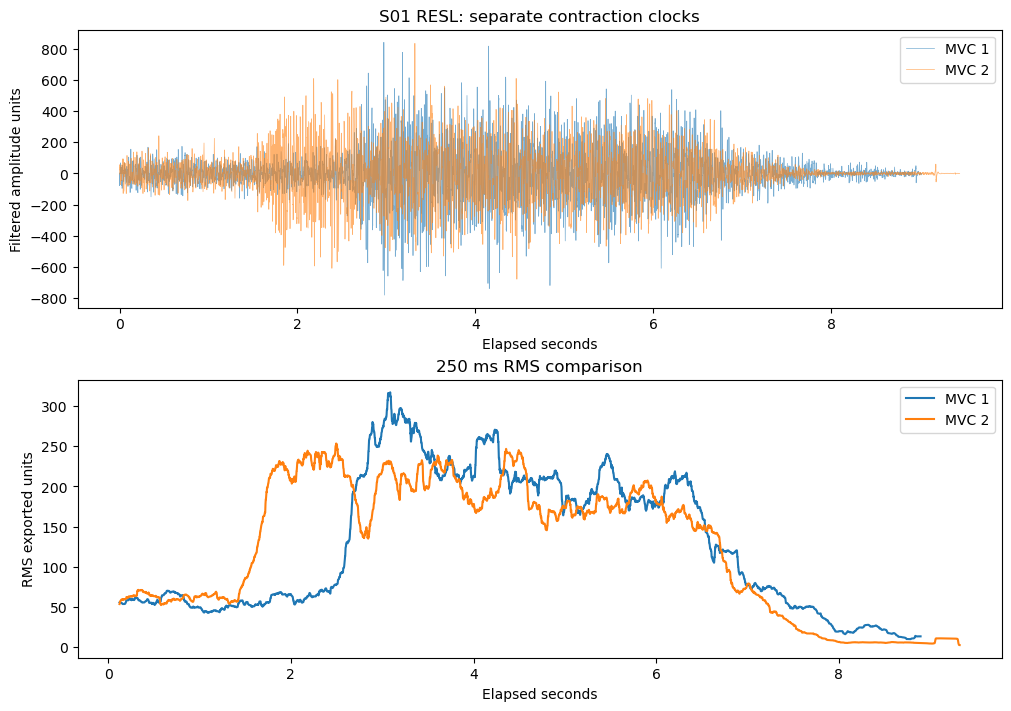

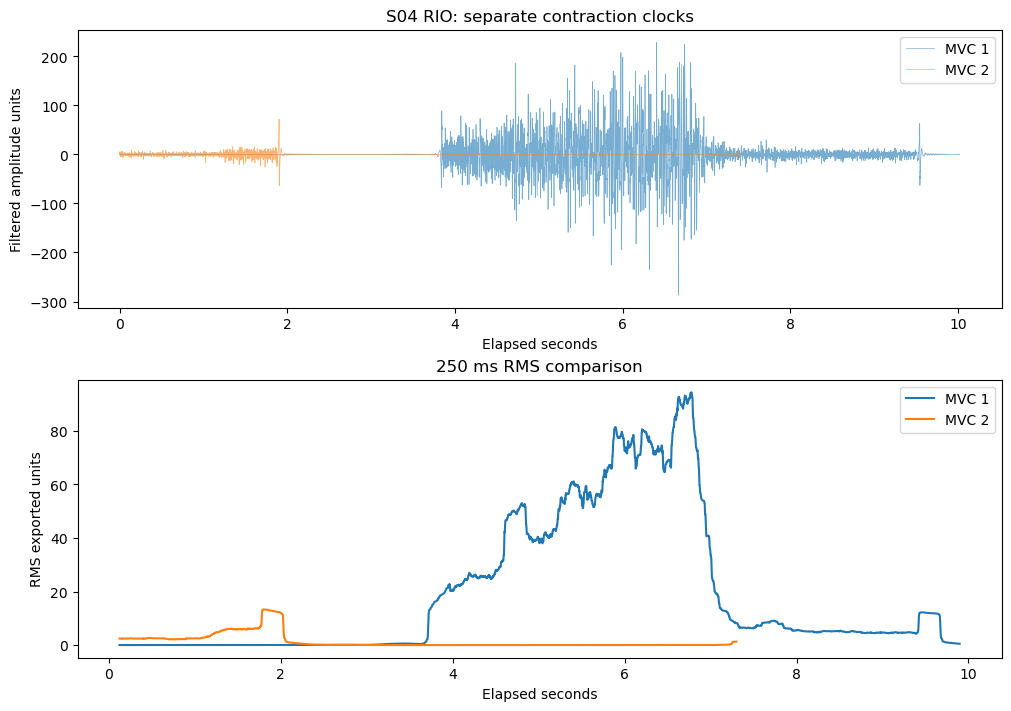

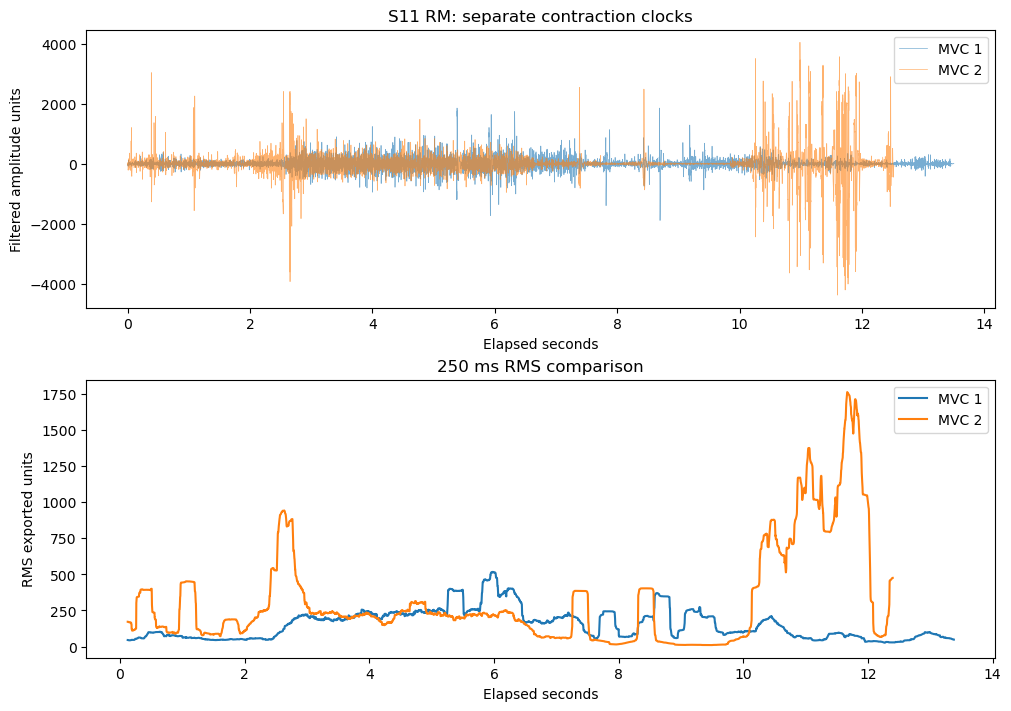

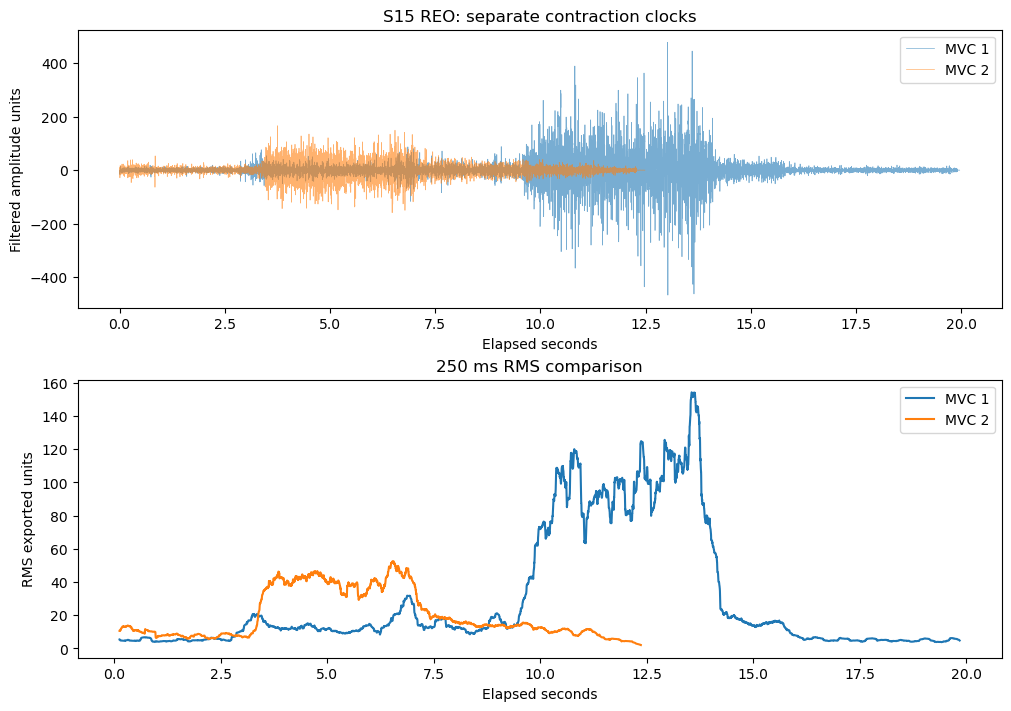

In [7]:
mvc_plot_count=0
for sid,frame in mvc.groupby("subject"):
    flagged=[]
    for channel,part in frame.groupby("channel"):
        refs=part.filtered_reference.dropna()
        if len(refs)>=2 and refs.min()>0 and refs.max()/refs.min()>2:
            flagged.append(channel)
    chosen=flagged if flagged else (["RESL"] if sid=="S01" else [])
    if not chosen:
        continue
    source=next((p for p in mat_files if subject_id(p.name)==sid),None)
    raw=loadmat(source,simplify_cells=True)
    root=next(v for k,v in raw.items() if not k.startswith("__") and isinstance(v,dict) and "MVC" in v)
    for channel in chosen:
        if mvc_plot_count>=MAX_DIAGNOSTIC_FIGURES:
            break
        fig,axes=plt.subplots(2,1,figsize=(10,7),constrained_layout=True)
        for j,rec in enumerate(entries(root.get("MVC")),1):
            fs=rate(rec.get("fs_MVC"))
            a=rec.get("MVC_data",{}).get(channel,[])
            filtered=bandpassed(a,fs)
            if filtered is not None:
                axes[0].plot(np.arange(len(filtered))/fs,filtered,label=f"MVC {j}",alpha=0.6,linewidth=0.5)
                trace=rms_trace(filtered,fs)
                axes[1].plot((np.arange(len(trace))+(len(filtered)-len(trace))/2)/fs,trace,label=f"MVC {j}")
        axes[0].set(title=f"{sid} {channel}: separate contraction clocks",ylabel="Filtered amplitude units",xlabel="Elapsed seconds")
        axes[1].set(title="250 ms RMS comparison",ylabel="RMS exported units",xlabel="Elapsed seconds")
        for ax in axes:
            ax.legend()
        output=FIG_DIR/f"{sid}_{channel}_MVC_review.png"
        fig.savefig(output,dpi=120)
        plot_paths.append(str(output.relative_to(RUN_DIR)))
        plt.show()
        plt.close(fig)
        mvc_plot_count+=1
    del raw,root

## Duplicate provenance and conservative inclusion ledger
All trial records involved in across-participant EMG or movement duplication are quarantined pending source review. For duplicates confined to one participant, a deterministic first entry is only a candidate representative. Conflicting event annotations hold the entire duplicate family. Force-only duplicates are reported but do not automatically exclude a movement/EMG experiment. No raw records are deleted.

In [8]:
duplicate_rows=[]
for (group,fingerprint),frame in hashes.dropna(subset=["sha256"]).groupby(["group","sha256"]):
    if len(frame)>1:
        for rec in frame.to_dict("records"):
            duplicate_rows.append(dict(rec,family=f"{group}_{fingerprint[:16]}",family_size=len(frame),cross_subject=frame.subject.nunique()>1))
duplicates=pd.DataFrame(duplicate_rows,columns=list(hashes.columns)+["family","family_size","cross_subject"])
trials["cross_subject_quarantine"]=False
trials["duplicate_nonrepresentative"]=False
trials["duplicate_event_conflict"]=False
trials["duplicate_families"]=""
for family,frame in duplicates[duplicates.group.isin(["Kinematic_data","sEMG"])].groupby("family"):
    ids=sorted(frame.trial_id.unique())
    affected=trials.trial_id.isin(ids)
    trials.loc[affected,"duplicate_families"]+=family+";"
    if frame.cross_subject.any():
        trials.loc[affected,"cross_subject_quarantine"]=True
    else:
        trials.loc[trials.trial_id.isin(ids[1:]),"duplicate_nonrepresentative"]=True
        if "events_json" in trials and trials.loc[affected,"events_json"].nunique()>1:
            trials.loc[affected,"duplicate_event_conflict"]=True
trials["primary_LI1_LI2_candidate"]=trials.LI.isin([1,2])
trials["secondary_LI1_LI2_LI3_S01_S10_candidate"]=trials.subject.isin([f"S{i:02d}" for i in range(1,11)]) & trials.LI.isin([1,2,3])
trials["structural_candidate"]=trials.pair_valid.fillna(False) & trials.movement_finite.fillna(False) & trials.events_ordered.fillna(False) & ~trials.cross_subject_quarantine & ~trials.duplicate_nonrepresentative & ~trials.duplicate_event_conflict
trials["trial_status"]=np.select([trials.cross_subject_quarantine,trials.duplicate_event_conflict,trials.duplicate_nonrepresentative,~trials.structural_candidate,trials.alignment_documented.fillna(False)],["quarantine_cross_subject_recording","hold_conflicting_duplicate_events","exclude_duplicate_candidate","hold_structural_review","documented_timing_pending_channel_review"],default="hold_alignment_review")
channels=channels.merge(trials[["trial_id","structural_candidate","alignment_documented","trial_status"]],on="trial_id",how="left",validate="many_to_one")
channels["channel_ready_for_reviewed_target"]=channels.structural_candidate & channels.alignment_documented.fillna(False) & channels.reference_review_accepted & channels.candidate_normalization_available & channels["std"].gt(0) & channels.nonfinite_fraction.eq(0) & channels.documented_phase_rms_percent_candidate_mvc.notna()
channels["target_for_main_project"]=channels.documented_phase_rms_percent_candidate_mvc.where(channels.channel_ready_for_reviewed_target)
display(duplicates)
display(trials.groupby("trial_status").size().rename("trials").to_frame())
display(channels.groupby("channel").agg(trials=("trial_id","size"),candidate_references=("candidate_normalization_available","sum"),reviewed_targets=("channel_ready_for_reviewed_target","sum")))

,subject,group,task,trial_id,sha256,family,family_size,cross_subject
0,S09,Ground_forces_and_moments,S09_Lift_LI3_2.TDF,S09::s09_lift_li3_2,585a5de21fa78f66d8607532a65c0fc70543df94f568de...,Ground_forces_and_moments_585a5de21fa78f66,2,False
1,S09,Ground_forces_and_moments,S09_Lift_LI3_3.TDF,S09::s09_lift_li3_3,585a5de21fa78f66d8607532a65c0fc70543df94f568de...,Ground_forces_and_moments_585a5de21fa78f66,2,False
2,S14,Ground_forces_and_moments,S14_Lift_LI2_1.TDF,S14::s14_lift_li2_1,7b767e371d64d76c6e797b5dc127ea325c519702b6edca...,Ground_forces_and_moments_7b767e371d64d76c,2,False
3,S14,Ground_forces_and_moments,S14_Lift_LI2_2.TDF,S14::s14_lift_li2_2,7b767e371d64d76c6e797b5dc127ea325c519702b6edca...,Ground_forces_and_moments_7b767e371d64d76c,2,False
4,S12,Ground_forces_and_moments,S12_Lift_LI2_1.TDF,S12::s12_lift_li2_1,90b070d1273fc026d1c41e10a3b24fb5e22473f6572651...,Ground_forces_and_moments_90b070d1273fc026,2,True
...,...,...,...,...,...,...,...,...
33,S04,sEMG,S04_Lift_LI3_3.TDF,S04::s04_lift_li3_3,af029a5c1fd2917fc208c0ad2e0217a97bcb781c7f075c...,sEMG_af029a5c1fd2917f,2,False
34,S05,sEMG,S05_Lift_LI3_2.TDF,S05::s05_lift_li3_2,cba12c991fca50d750b2cb94f026f53374868fd1ac156e...,sEMG_cba12c991fca50d7,2,False
35,S05,sEMG,S05_Lift_LI3_3.TDF,S05::s05_lift_li3_3,cba12c991fca50d750b2cb94f026f53374868fd1ac156e...,sEMG_cba12c991fca50d7,2,False
36,S14,sEMG,S14_Lift_LI2_1.TDF,S14::s14_lift_li2_1,f215cfff03f85e23d62505206bebbc6f73105da92514a5...,sEMG_f215cfff03f85e23,2,False


,trials
trial_status,
exclude_duplicate_candidate,3
hold_alignment_review,121
hold_conflicting_duplicate_events,6
quarantine_cross_subject_recording,2


,trials,candidate_references,reviewed_targets
channel,,,
LEO,132,132,0
LESI,132,132,0
LESL,132,132,0
LIO,132,132,0
LLD,132,132,0
LM,132,132,0
LRAM,132,132,0
LRAS,132,132,0
REO,132,132,0


## Review templates and cohort decision
Templates are deliberately unapproved. A timing review needs acquisition/export evidence for a common time origin and event indexing. Duration subtraction, centered padding and visual muscle activation are hypotheses, not proof. Ambiguous duplicated or misassigned trials remain outside the candidate analysis. Resolving such records requires a documented source correction and another audit.

The primary cohort candidate uses LI1/LI2. The three-condition sensitivity cohort uses S01–S10. Neither becomes a final analysis cohort until the ledgers pass review.

In [9]:
alignment_template=trials[["trial_id","motion_sha256","emg_sha256"]].copy()
alignment_template["event_index_base"]=""
alignment_template["emg_offset_s"]=""
alignment_template["alignment_approved"]=False
alignment_template["evidence_source"]=""
alignment_template["reviewer"]=""
channel_template=channels[["subject","channel","mvc_sha256_1","mvc_sha256_2"]].drop_duplicates(["subject","channel"]).copy()
channel_template["channel_approved"]=False
channel_template["reference_method"]="max_filtered_rms_p95_250ms"
channel_template["units_confirmed"]=""
channel_template["evidence_source"]=""
channel_template["reviewer"]=""
coverage=trials.pivot_table(index="subject",columns="LI",values="trial_id",aggfunc="size",fill_value=0).reindex(columns=[1,2,3],fill_value=0)
mvc_review=channels[["subject","channel","mvc_entries","positive_mvc_references","mvc_repeat_ratio","mvc_ratio_review_flag","candidate_reference"]].drop_duplicates(["subject","channel"])
display(coverage)
display(mvc_review[mvc_review.mvc_ratio_review_flag | mvc_review.positive_mvc_references.lt(2)])
display(trials.sort_values("duration_difference_s",ascending=False)[["subject","task","motion_seconds","emg_seconds","duration_difference_s"]].head(12))
summary={"version":"2.0","project_root":str(PROJECT_ROOT),"data_root":str(DATA_ROOT),"participants_loaded":len({r["subject"] for r in file_rows}),"trial_rows":len(trials),"parser_issues":len(issues),"structural_candidates":int(trials.structural_candidate.sum()),"cross_subject_quarantined_trials":int(trials.cross_subject_quarantine.sum()),"duplicate_event_conflict_trials":int(trials.duplicate_event_conflict.sum()),"documented_alignment_trials":int(trials.alignment_documented.fillna(False).sum()),"reviewed_target_rows":int(channels.channel_ready_for_reviewed_target.sum()),"mvc_channels_flagged_ratio_gt2":int(mvc_review.mvc_ratio_review_flag.sum()),"INAIL2_decision":"Not required to resolve INAIL1. Consider compatible external validation after valid INAIL1 targets and within-condition added value are established.","timing_conclusion":"Hypotheses inspected; only evidence-backed reviewer entries bound to source hashes can change documented timing status.","training_status":"not_trained","next_action":"Inspect duplicate provenance, timing/source exports and MVC plots; resolve the ledger before model development."}
print(json.dumps(summary,indent=2))

LI,1,2,3
subject,,,
S01,3,3,3
S02,3,3,3
S03,3,3,3
S04,3,3,3
S05,3,3,3
S06,3,3,3
S07,3,3,3
S08,3,3,3
S09,3,3,3


,subject,channel,mvc_entries,positive_mvc_references,mvc_repeat_ratio,mvc_ratio_review_flag,candidate_reference
439,S04,RIO,2,2,12.531264,True,76.771035
1442,S11,RM,2,2,2.931445,True,1091.299874
1830,S15,REO,2,2,2.461147,True,110.193429


,subject,task,motion_seconds,emg_seconds,duration_difference_s
35,S04,s04_lift_li3_3,7.070588,18.006,10.935412
34,S04,s04_lift_li3_2,7.070588,18.006,10.935412
125,S16,s16_lift_li2_3,6.744118,8.930,2.185882
81,S10,s10_lift_li1_1,8.797059,10.914,2.116941
107,S13,s13_lift_li2_3,5.744118,7.857,2.112882
33,S04,s04_lift_li3_1,9.379412,11.469,2.089588
91,S11,s11_lift_li1_2,4.897059,6.981,2.083941
63,S08,s08_lift_li1_1,14.447059,16.528,2.080941
13,S02,s02_lift_li2_2,7.947059,10.021,2.073941
130,S17,s17_lift_li2_2,8.547059,10.589,2.041941


{
  "version": "2.0",
  "project_root": "/home/rafsan/Documents/GitHub/IPEXBIO/Project_A",
  "data_root": "/home/rafsan/Downloads/INAIL_1/Dataset1/DATA",
  "participants_loaded": 17,
  "trial_rows": 132,
  "parser_issues": 0,
  "structural_candidates": 121,
  "cross_subject_quarantined_trials": 2,
  "duplicate_event_conflict_trials": 6,
  "documented_alignment_trials": 0,
  "reviewed_target_rows": 0,
  "mvc_channels_flagged_ratio_gt2": 3,
  "INAIL2_decision": "Not required to resolve INAIL1. Consider compatible external validation after valid INAIL1 targets and within-condition added value are established.",
  "timing_conclusion": "Hypotheses inspected; only evidence-backed reviewer entries bound to source hashes can change documented timing status.",
  "training_status": "not_trained",
  "next_action": "Inspect duplicate provenance, timing/source exports and MVC plots; resolve the ledger before model development."
}


## Export results and ZIP inside Project A

In [10]:
def clean_json(value):
    if isinstance(value,dict):
        return {str(k):clean_json(v) for k,v in value.items()}
    if isinstance(value,(list,tuple)):
        return [clean_json(v) for v in value]
    if isinstance(value,np.generic):
        return clean_json(value.item())
    if isinstance(value,float) and not np.isfinite(value):
        return None
    return value

def save_json(name,value):
    (RUN_DIR/name).write_text(json.dumps(clean_json(value),indent=2,ensure_ascii=False,allow_nan=False),encoding="utf-8")

tables={"trial_inclusion_ledger":trials,"channel_inclusion_ledger":channels,"mvc_filtered_diagnostics":mvc,"mvc_channel_review":mvc_review,"duplicate_provenance":duplicates,"stream_hashes":hashes,"source_files":pd.DataFrame(file_rows),"source_tdf_inventory":tdf_inventory,"condition_coverage":coverage.reset_index(),"alignment_review_template":alignment_template,"channel_review_template":channel_template}
for name,frame in tables.items():
    if not len(frame.columns):
        frame=pd.DataFrame(columns=["no_records"])
    frame.to_csv(RUN_DIR/f"{name}.csv",index=False)
    save_json(f"{name}.json",frame.to_dict("records"))
save_json("protocol_extraction.json",protocol)
save_json("participant_workbooks.json",workbooks)
save_json("errors.json",issues)
save_json("review_inputs.json",{"alignment":alignment_review.to_dict("records"),"channels":channel_review.to_dict("records")})
save_json("audit_summary.json",summary)
versions={}
for package in ["numpy","pandas","scipy","matplotlib","openpyxl"]:
    try:
        versions[package]=importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        versions[package]="not_installed"
save_json("environment.json",{"python":sys.version,"platform":platform.platform(),"packages":versions})
readme=["Project A INAIL1 readiness V2",json.dumps(summary,indent=2),"Primary outputs: trial_inclusion_ledger.csv, channel_inclusion_ledger.csv, duplicate_provenance.csv, mvc_channel_review.csv, protocol_extraction.json and figures.","No training performed. Candidate normalization is filtered RMS based and needs contraction/unit review. Current snapshots preserve all source records. Across-participant duplicated signal trials are quarantined. Duplicate event conflicts are held. No evidence-free offset is selected.","Review templates: set evidence and reviewer only after actual source verification. emg_offset_s is added to movement elapsed seconds. source hashes must match. Reference method is fixed to max_filtered_rms_p95_250ms. Rerun V2 with explicit review-file configuration paths.","All outputs remain under PROJECT_ROOT/results/INAIL1_Readiness_V2. Archive contains diagnostic tables, protocol text, participant descriptors and figures but no raw MATLAB/TDF arrays."]
(RUN_DIR/"READ_ME_FIRST.txt").write_text("\n\n".join(readme),encoding="utf-8")
archive_dir=PROJECT_ROOT/"archives"
archive_dir.mkdir(exist_ok=True)
zip_path=archive_dir/f"ProjectA_INAIL1_Readiness_V2_{RUN_DIR.name}.zip"
with zipfile.ZipFile(zip_path,"w",zipfile.ZIP_DEFLATED) as archive:
    for p in sorted(RUN_DIR.rglob("*")):
        if p.is_file():
            archive.write(p,str(p.relative_to(RUN_DIR)))
print("V2 COMPLETE")
print("Results:",RUN_DIR)
print("Upload ZIP:",zip_path)
print("Upload the executed V2 notebook as well.")

V2 COMPLETE
Results: /home/rafsan/Documents/GitHub/IPEXBIO/Project_A/results/INAIL1_Readiness_V2/run_20261113T052750_196646Z
Upload ZIP: /home/rafsan/Documents/GitHub/IPEXBIO/Project_A/archives/ProjectA_INAIL1_Readiness_V2_run_20261113T052750_196646Z.zip
Upload the executed V2 notebook as well.


In [11]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import re
import zipfile

PROJECT_ROOT = Path("/home/rafsan/Documents/GitHub/IPEXBIO/Project_A")
DATA_ROOT = Path.home() / "Downloads/INAIL_1/Dataset1/DATA"

SELECTED_FILES = [
    DATA_ROOT / "S01/Proprietary/TDF_format/S01_Lift_LI1_1.TDF",
    DATA_ROOT / "S04/Proprietary/TDF_format/S04_Lift_LI3_2.TDF",
]

missing = [str(p) for p in SELECTED_FILES if not p.is_file()]
if missing:
    raise FileNotFoundError("\n".join(missing))

run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
output_dir = PROJECT_ROOT / "results" / "INAIL1_TDF_Inspection" / run_id
archive_dir = PROJECT_ROOT / "archives"

output_dir.mkdir(parents=True, exist_ok=False)
archive_dir.mkdir(parents=True, exist_ok=True)

inventory = []
for path in sorted(DATA_ROOT.rglob("*")):
    if path.is_file() and path.suffix.lower() == ".tdf":
        if "__MACOSX" not in path.parts and not path.name.startswith("._"):
            inventory.append({
                "relative_path": str(path.relative_to(DATA_ROOT)),
                "bytes": path.stat().st_size,
            })

reports = []
for path in SELECTED_FILES:
    payload = path.read_bytes()
    ascii_strings = [
        {
            "byte_offset": match.start(),
            "text": match.group().decode("ascii"),
        }
        for match in re.finditer(rb"[\x20-\x7e]{6,}", payload)
    ]

    utf16_strings = [
        {
            "byte_offset": match.start(),
            "text": match.group().decode("utf-16-le"),
        }
        for match in re.finditer(rb"(?:[\x20-\x7e]\x00){6,}", payload)
    ]

    report = {
        "file": str(path.relative_to(DATA_ROOT)),
        "bytes": len(payload),
        "sha256": hashlib.sha256(payload).hexdigest(),
        "first_512_bytes_hex": payload[:512].hex(" "),
        "ascii_string_count": len(ascii_strings),
        "ascii_strings_first_300": ascii_strings[:300],
        "utf16_le_string_count": len(utf16_strings),
        "utf16_le_strings_first_300": utf16_strings[:300],
        "interpretation": "Raw binary inspection; timing fields have not been decoded or verified.",
    }
    reports.append(report)

    (output_dir / f"{path.stem}_header.bin").write_bytes(payload[:4096])
    (output_dir / f"{path.stem}_inspection.json").write_text(
        json.dumps(report, indent=2),
        encoding="utf-8",
    )

    print("\nFILE:", path.name)
    print("SIZE:", len(payload), "bytes")
    print("FIRST 64 BYTES:", payload[:64].hex(" "))
    print("FIRST READABLE STRINGS:")
    for item in ascii_strings[:20]:
        print(item["byte_offset"], repr(item["text"][:160]))

(output_dir / "tdf_inventory.json").write_text(
    json.dumps(inventory, indent=2),
    encoding="utf-8",
)

zip_path = archive_dir / f"ProjectA_INAIL1_TDF_Inspection_{run_id}.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for path in sorted(output_dir.iterdir()):
        archive.write(path, arcname=f"inspection/{path.name}")
    for path in SELECTED_FILES:
        archive.write(
            path,
            arcname=f"original_TDF/{path.relative_to(DATA_ROOT).as_posix()}",
        )

print("\nCOMPLETE")
print("TDF files inventoried:", len(inventory))
print("Inspection folder:", output_dir)
print("UPLOAD THIS ZIP:", zip_path)
print("ZIP size:", round(zip_path.stat().st_size / 1e6, 2), "MB")


FILE: S01_Lift_LI1_1.TDF
SIZE: 3126268 bytes
FIRST 64 BYTES: 82 4b 60 41 d3 11 84 ca 60 00 b6 ac 16 68 0c 08 01 00 00 00 0e 00 00 00 7c 43 1f 77 30 44 1f 77 b7 9e db 57 b7 9e db 57 9d 89 a7 66 50 04 00 00 c0 75 b1 0d ff ff 00 00 00 00 00 00 40 ec b1 0d
FIRST READABLE STRINGS:
320 '10P3_r should'
1343 '=10P3_r e'
1600 '10P3_r elbow'
1855 '=10P3_r radio'
2113 '0P3_r e('
2592 '1G_Right'
2608 's internus abdom10P3_r ulna'
2880 '10P3_R3M'
3328 '1G_Left Latissimus Dorsi'
3392 '10P3_R3M'
3408 '1G_Left '
3872 '1G_EMG Signal 2'
3952 '1G_Left Rectus abdominis'
4558 'sterno'
4569 'sacrum'
4576 'r should'
4585 'r elbow'
4593 'r ulna'
4600 'r radio'
4612 'r asis'

FILE: S04_Lift_LI3_2.TDF
SIZE: 2627620 bytes
FIRST 64 BYTES: 82 4b 60 41 d3 11 84 ca 60 00 b6 ac 16 68 0c 08 01 00 00 00 0e 00 00 00 7c 13 bc 76 01 00 00 c0 a1 12 48 57 a2 12 48 57 5c 0e b3 62 00 00 00 00 00 00 00 00 00 00 00 00 00 00 00 00 00 00 00 00
FIRST READABLE STRINGS:
243 'C:\\Users\\'
276 '\\\\TIWANA\\Users'
291 'Tiwana  Varrecc